# Task1: رحلة داتا السكري

## 1. فهم المشكلة

الهدف من المشروع هو معرفة العوامل المرتبطة بالإصابة بالسكري، حتى تساعد النتائج عيادة السكري في تحديد الفئات الأكثر عرضة والتركيز على الفحص المبكر.

- Dataset: Pima Indians Diabetes
- عدد الصفوف: 768
- Target: Outcome
- Outcome = 1: مصابة بالسكري
- Outcome = 0: غير مصابة بالسكري

## 2. أول نظرة

في البداية بنفحص البيانات ونتعرف على حجمها، أنواع الأعمدة، القيم المفقودة، التكرار والإحصائيات.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# قراءة البيانات
df = pd.read_csv('/content/diabetes.csv')

# عرض أول 5 صفوف
display(df.head())

# حجم البيانات
print("Shape:", df.shape)

# معلومات الأعمدة
df.info()

# الإحصائيات
display(df.describe())

# القيم المفقودة
print("Missing Values:")
print(df.isnull().sum())

# الصفوف المكررة
print("Duplicates:", df.duplicated().sum())

# عدد القيم المختلفة
print("Unique Values:")
print(df.nunique())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Shape: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Duplicates: 0
Unique Values:
Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64


In [2]:
# فحص الأصفار في الأعمدة الطبية
columns = ['Glucose', 'BloodPressure', 'SkinThickness',
           'Insulin', 'BMI']

for col in columns:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


## 3. EDA

في هذه الخطوة بنستكشف توزيع البيانات ونشوف العلاقة بين بعض الأعمدة وعمود Outcome.

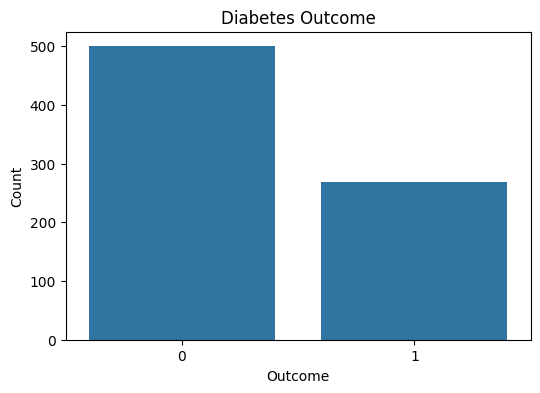

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [3]:
# توزيع حالة السكري

plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Outcome')

plt.title('Diabetes Outcome')
plt.xlabel('Outcome')
plt.ylabel('Count')

plt.show()

print(df['Outcome'].value_counts())
print(df['Outcome'].value_counts(normalize=True) * 100)

يوضح الرسم توزيع حالات الإصابة بالسكري، ونلاحظ أن نسبة غير المصابات تمثل 65.10% من البيانات، بينما تمثل المصابات 34.90%.

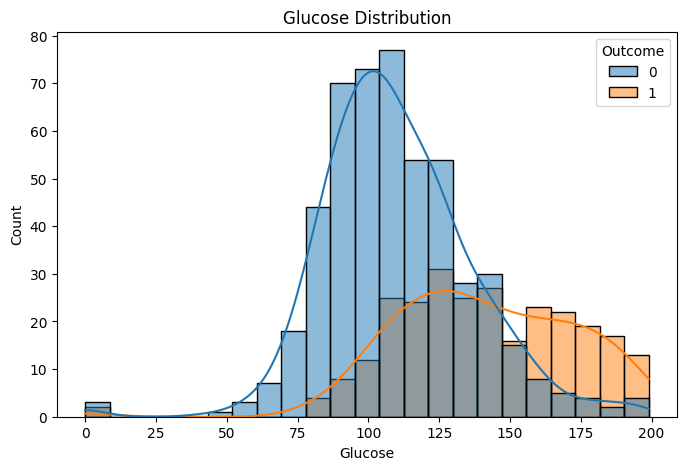

In [4]:
# توزيع Glucose

plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Glucose', hue='Outcome',
             kde=True)

plt.title('Glucose Distribution')
plt.show()

نلاحظ أن المصابات بالسكري يظهر لديهن مستويات

Glucose

أعلى بشكل عام مقارنة بغير المصابات، حيث يتركز توزيعهن بشكل أكبر بين 125 و180 تقريبًا.

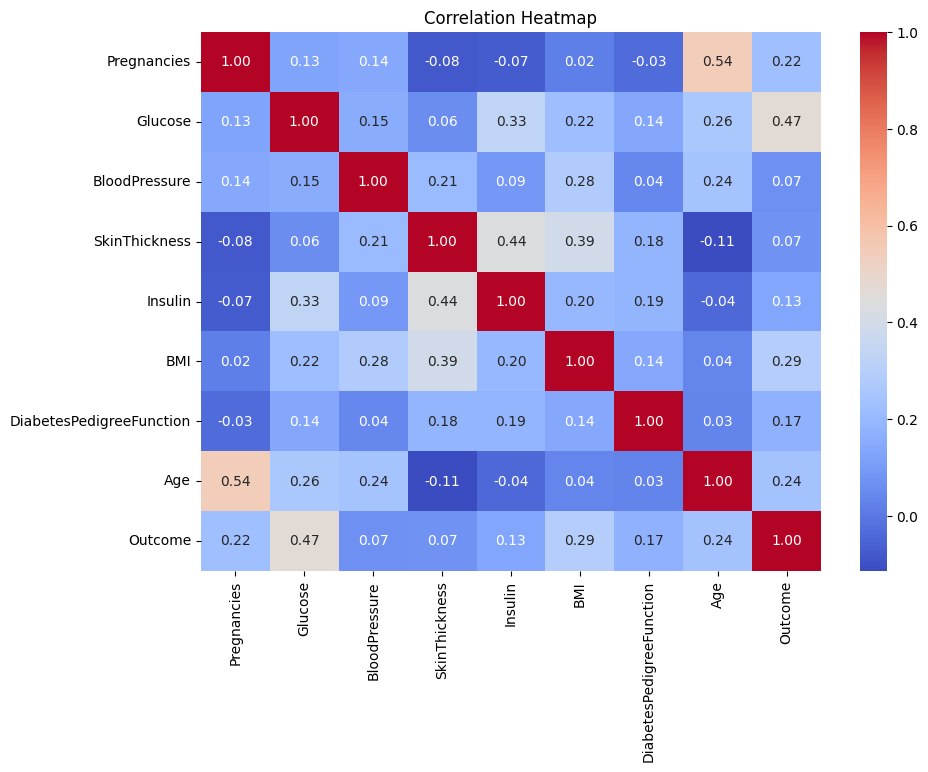

In [5]:
# Correlation Heatmap

plt.figure(figsize=(10,7))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

يوضح الرسم نتائج الارتباط مع عمود Outcome:

Glucose: أعلى ارتباط بقيمة 0.47

BMI: ارتباط بقيمة 0.29

Age: ارتباط بقيمة 0.24

بينما كان الارتباط ضعيفًا في:

BloodPressure: 0.07

SkinThickness: 0.07

## 4. Data Cleaning + Decision Log

بعد فحص البيانات، لاحظت وجود أصفار في بعض الأعمدة الطبية، وقد تكون هذه القيم غير صحيحة وتمثل بيانات مفقودة

لذلك قررت فحصها واستبدالها بالقيم المفقودة، ثم تعويضها باستخدام Median

In [6]:
# حفظ عدد الصفوف قبل التنظيف
before = len(df)

# حذف الصفوف المكررة
duplicates = df.duplicated().sum()
df = df.drop_duplicates()

print("Duplicates removed:", duplicates)

# الأعمدة التي لا يعتبر الصفر فيها قيمة طبية منطقية
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI']

# استبدال الأصفار بقيم مفقودة
for col in zero_columns:
    count = (df[col] == 0).sum()
    df[col] = df[col].replace(0, np.nan)
    print(col, "replaced:", count)

# تعويض القيم المفقودة بالوسيط
for col in zero_columns:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

# فحص البيانات بعد التنظيف
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nRows Before:", before)
print("Rows After:", len(df))

Duplicates removed: 0
Glucose replaced: 5
BloodPressure replaced: 35
SkinThickness replaced: 227
Insulin replaced: 374
BMI replaced: 11

Missing Values After Cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Rows Before: 768
Rows After: 768


### Decision Log

1. لم يتم حذف أي صفوف مكررة، لأن عدد التكرارات كان 0.

2. تم استبدال الأصفار في الأعمدة الطبية بقيم مفقودة، لأن الصفر لا يمثل قياسًا صحيحًا لهذه الأعمدة.

3. كان عمود Insulin يحتوي على أكبر عدد من الأصفار (374)، وتم الاحتفاظ به وتعويض القيم باستخدام Median.

4. تم استخدام Median لتعويض القيم المفقودة لتقليل تأثير القيم المتطرفة.

5. بعد التنظيف، لم تعد هناك قيم مفقودة، وبقي عدد الصفوف 768 دون تغيير.

## 5. Feature Engineering

في هذه الخطوة بضيف أعمدة جديدة تساعد في تقسيم البيانات إلى فئات أسهل في التحليل.

In [7]:
# تقسيم BMI إلى فئات
df['BMI_Category'] = pd.cut(
    df['BMI'],
    bins=[0, 18.5, 25, 30, float('inf')],
    labels=['Low', 'Normal', 'Overweight', 'High']
)

# تقسيم العمر إلى فئات
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 30, 40, 50, float('inf')],
    labels=['Young', 'Adult', 'Middle', 'Older']
)

display(df[['BMI', 'BMI_Category', 'Age', 'Age_Group']].head())

,BMI,BMI_Category,Age,Age_Group
0,33.6,High,50,Middle
1,26.6,Overweight,31,Adult
2,23.3,Normal,32,Adult
3,28.1,Overweight,21,Young
4,43.1,High,33,Adult


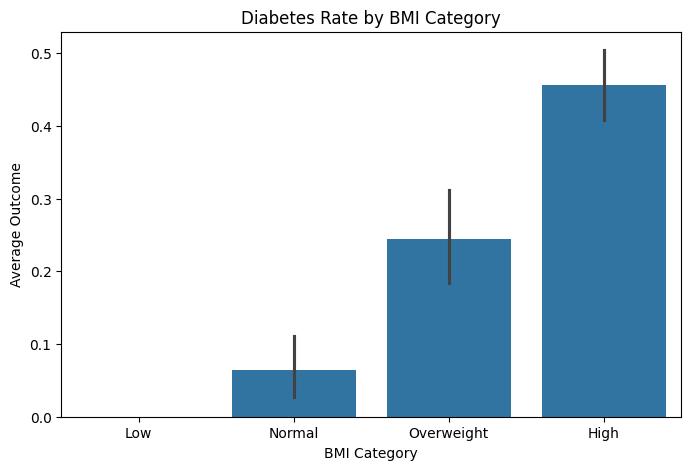

BMI_Category
Low           0.000000
Normal        0.064815
Overweight    0.244444
High          0.455882
Name: Outcome, dtype: float64


In [8]:
plt.figure(figsize=(8,5))

sns.barplot(data=df, x='BMI_Category', y='Outcome')

plt.title('Diabetes Rate by BMI Category')
plt.xlabel('BMI Category')
plt.ylabel('Average Outcome')

plt.show()

# عرض نسبة الإصابة لكل فئة
print(df.groupby('BMI_Category', observed=True)['Outcome'].mean())

يوضح الرسم أن نسبة الإصابة بالسكري ترتفع مع ارتفاع BMI:

- Low: 0%
- Normal: 6.48%
- Overweight: 24.44%
- High: 45.59%

كانت أعلى نسبة إصابة في فئة High.

## 6. Feature Selection

في هذه الخطوة بقارن ارتباط الأعمدة مع
Outcome

واحدد الأعمدة التي نحتفظ بها في البيانات النهائية

In [9]:
# حساب الارتباط مع Outcome
correlation = df.corr(numeric_only=True)['Outcome'].drop('Outcome')

# ترتيب الارتباطات
display(correlation.sort_values(ascending=False))

,Outcome
Glucose,0.492782
BMI,0.312038
Age,0.238356
Pregnancies,0.221898
SkinThickness,0.214873
Insulin,0.203790
DiabetesPedigreeFunction,0.173844
BloodPressure,0.165723


نلاحظ أن Glucose لديه أعلى ارتباط،

بينما BloodPressure لديه أضعف ارتباط.

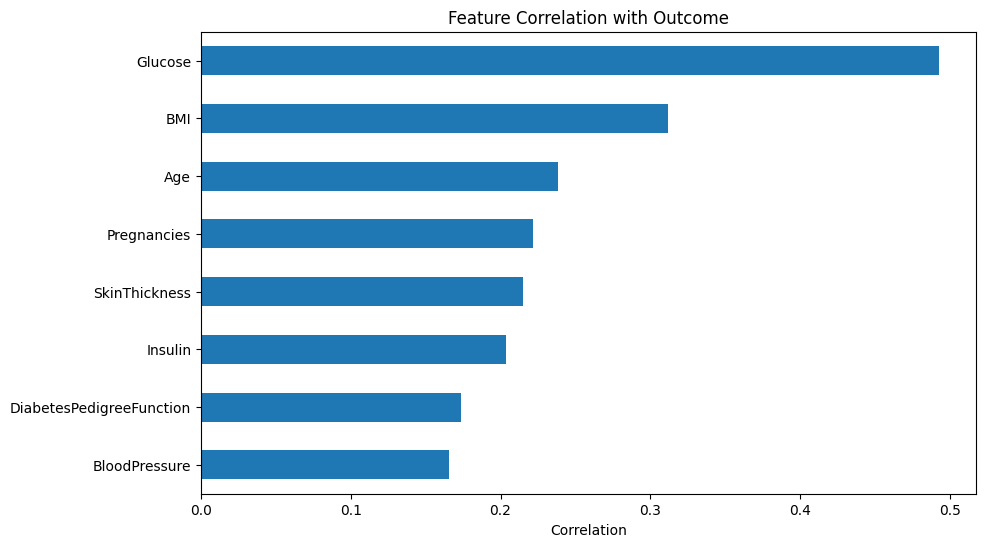

In [10]:
# رسم النتائج

plt.figure(figsize=(10,6))

correlation.sort_values().plot(kind='barh')

plt.title('Feature Correlation with Outcome')
plt.xlabel('Correlation')

plt.show()

يوضح الرسم ترتيب الأعمدة حسب ارتباطها بـ
Outcome

كان Glucose الأعلى بقيمة 0.493

يليه BMI بقيمة 0.312

بينما سجل BloodPressure أقل ارتباط بقيمة 0.166.

**مراجعة الارتباطات واتخاذ القرار**

بما أن جميع الأعمدة لديها ارتباط موجب مع Outcome،

وأقل ارتباط بينها 0.166، قررنا الاحتفاظ بجميع الأعمدة الأصلية،

لأنه لا يوجد سبب واضح لحذف أي عمود بناءً على نتائج الارتباط وحدها.

وسأحتفظ بالأعمدة الجديدة
BMI_Category و Age_Group
بعد تحويلها إلى أرقام.

In [11]:
# تحويل الفئات إلى أرقام
df['BMI_Category'] = df['BMI_Category'].cat.codes
df['Age_Group'] = df['Age_Group'].cat.codes

# إنشاء البيانات النهائية
model_ready = df.copy()

display(model_ready.head())

print("Final Shape:", model_ready.shape)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_Category,Age_Group
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1,3,2
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0,2,1
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1,1,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,2,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,3,1


Final Shape: (768, 11)


In [12]:
# حساب الارتباط بعد إضافة الأعمدة الجديدة
correlation = model_ready.corr()['Outcome'].drop('Outcome')

# ترتيب الارتباطات
display(correlation.sort_values(ascending=False))

,Outcome
Glucose,0.492782
BMI,0.312038
BMI_Category,0.307594
Age_Group,0.261957
Age,0.238356
Pregnancies,0.221898
SkinThickness,0.214873
Insulin,0.203790
DiabetesPedigreeFunction,0.173844
BloodPressure,0.165723


### Feature Selection Decision

يوضح الجدول التالي قرار الاحتفاظ بالأعمدة بناءً على نتائج الارتباط مع Outcome:


| Feature | Correlation | Decision |
|---|---:|---|
| Glucose | 0.493 | Keep |
| BMI | 0.312 | Keep |
| BMI_Category | 0.308 | Keep |
| Age_Group | 0.262 | Keep |
| Age | 0.238 | Keep |
| Pregnancies | 0.222 | Keep |
| SkinThickness | 0.215 | Keep |
| Insulin | 0.204 | Keep |
| DiabetesPedigreeFunction | 0.174 | Keep |
| BloodPressure | 0.166 | Keep |

قررنا الاحتفاظ بجميع الأعمدة لأن جميعها أظهرت ارتباطًا موجبًا مع
Outcome

لم يكن هناك سببًا كافيًا لاستبعاد أي عمود بناءً على نتائج الارتباط.

In [13]:
# حفظ البيانات النهائية
model_ready.to_csv('/content/diabetes_model_ready.csv', index=False)

print("File saved successfully!")
print("Final Shape:", model_ready.shape)

File saved successfully!
Final Shape: (768, 11)


## 7. Results & Recommendations

في هذه الخطوة سيتم مراجعة أهم العوامل المرتبطة بالإصابة بالسكري، ونستخدم النتائج لتحديد التوصيات المناسبة للعيادة.

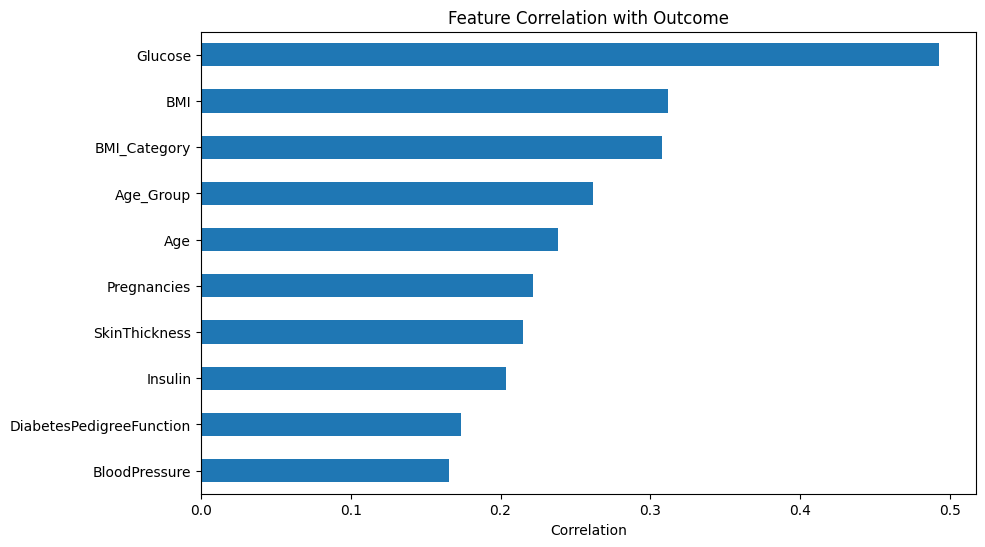

In [14]:
plt.figure(figsize=(10,6))

correlation.sort_values().plot(kind='barh')

plt.title('Feature Correlation with Outcome')
plt.xlabel('Correlation')

plt.show()

أعلى ارتباط: Glucose بقيمة 0.493

ثاني أعلى ارتباط: BMI بقيمة 0.312

أقل ارتباط: BloodPressure بقيمة 0.166

### النتائج والتوصيات

من خلال تحليل البيانات، لاحظنا أن Glucose و BMI من أكثر العوامل ارتباطًا بالإصابة بالسكري.

كما أظهرت النتائج ارتفاع نسبة الإصابة مع ارتفاع فئات BMI، حيث وصلت إلى 45.59% في فئة High.

نوصي العيادة بالاهتمام بفحص مستويات Glucose ومؤشر BMI، والتركيز على الفئات التي تظهر لديها مستويات مرتفعة منهما.

# Task2: ملخص لطبيب العيادة

### 1. أهم العوامل المرتبطة بالسكري

من خلال تحليل البيانات، لاحظت أن أكثر ثلاثة أعمدة ارتباطًا بالسكري هي:

- Glucose بقيمة 0.493.
- BMI بقيمة 0.312.
- BMI_Category بقيمة 0.308.

وكان Glucose هو الأعلى ارتباطًا بـ Outcome، وهذا واضح أيضًا في الرسم.

### 2. أكبر مشكلة في البيانات

أكبر مشكلة واجهتني كانت وجود أصفار في بعض الأعمدة الطبية، خصوصًا

Insulin الذي احتوى على 374 صفرًا.

تعاملت معها باعتبارها قيمًا مفقودة، وبعدها عوضتها باستخدام Median، وبعد التنظيف أصبحت البيانات بدون قيم مفقودة.

### 3. التوصية للعيادة

أنصح بالاهتمام بفحص

GlucoseوBMI

خصوصًا أن نسبة الإصابة كانت أعلى في فئة
BMI المرتفعة

ووصلت إلى %45.59

### 4. حدود النتائج

رغم وجود ارتباط بين بعض العوامل والإصابة بالسكري، إلا أن هذا لا يعني أنها السبب المباشر للإصابة، فالبيانات توضح العلاقات فقط ولا تثبت الأسباب.